
# AI Programming with Python Final Exam

**Name: Kawsar Jamil**

**Course Email:**  Kawsarjamil726@gmail.com


## End of Assignment

Before submitting:
- Run all cells from top to bottom.  
- Check that all answer sections are filled.  
- Instruction video অনুযায়ী আমাদের দেয়া Colab ফাইলটি থেকে প্রথম একটি Save copy in drive করে নিবা। এরপর Google colab এর মধ্যে কোডগুলো করবে এবং সেই ফাইলটি ‘Anyone with the link’ & ‘View’ Access দিয়ে ফাইলটির Shareble Link টি সাবমিট করবে।

# 0) Starter Code (Run First)

In [ ]:
# You must run this code and use this dataset for all questions
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
num_students = 50

# Student data
student_ids = np.arange(201, 201 + num_students)
student_ages = np.random.randint(15, 22, num_students)
student_scores = np.random.randint(40, 100, num_students)
student_attendance = np.random.randint(60, 100, num_students)  # percentage

departments_list = [
    "Science",
    "Commerce",
    "Arts",
    "Computer Science",
    "Mathematics",
    "English",
    "Physics",
    "Chemistry",
    "Biology",
    "Economics"
]

student_departments = np.random.choice(departments_list, num_students)

grade_conditions = [
    student_scores >= 80,
    (student_scores >= 65) & (student_scores < 80),
    (student_scores >= 50) & (student_scores < 65),
    student_scores < 50
]
grade_values = ["A", "B", "C", "F"]
student_grades = np.select(grade_conditions, grade_values, default="F")

# Create DataFrame
data = pd.DataFrame({
    "student_id": student_ids,
    "student_age": student_ages,
    "score": student_scores,
    "attendance": student_attendance,
    "department": student_departments,
    "grade": student_grades
})

# Save dataset
data.to_csv("school_data.csv", index=False)

# Question 01: [ Marks 10 ]

Use NumPy arrays from the score and attendance columns. Print both arrays and display:

* Data type
* Number of dimensions
* Shape
* Total number of elements

# Write Answer 01:


In [ ]:
print(student_scores)
print(student_scores.dtype)
print(student_scores.ndim)
print(student_scores.shape)
print(student_scores.size)
print("\n")
print(student_attendance)
print(student_attendance.dtype)
print(student_attendance.ndim)
print(student_attendance.shape)
print(student_attendance.size)

[76 90 46 60 48 78 57 43 64 99 53 89 97 48 65 92 41 59 67 86 99 46 83 47
 86 74 53 56 75 89 79 43 41 45 93 81 43 93 68 57 65 83 73 49 75 53 70 87
 54 47]
int64
1
(50,)
50


[73 82 99 80 75 77 83 85 84 88 74 60 84 66 68 83 60 67 83 70 76 67 94 94
 92 64 98 87 66 68 67 71 93 92 82 83 96 94 99 81 86 94 60 94 96 73 62 60
 64 85]
int64
1
(50,)
50


# Question 02: [ Marks 10 ]

## Using NumPy functions on :

* Find the maximum and minimum score
* Calculate the average score
* Calculate the average attendance

Then, extract students who:

* Have a score greater than the average score

Print:

* The filtered score array

## Write Answer 02:


In [ ]:
maxi=student_scores.max()
print(maxi)
mini=student_scores.min()
print(mini)
sc_avg=np.mean(student_scores)
print(sc_avg)
attndnc_avg=np.mean(student_attendance)
print(attndnc_avg)

99
41
67.3
79.58


In [ ]:
mask=np.where(student_scores>sc_avg)
# print(mask)
# student_ids[student_scores>sc_avg]
new_ar=student_scores[mask]
print(new_ar)
# print("\n")
# mask2=(data['score']>data['score'].mean())
# # print(mask)
# # student_ids[student_scores>sc_avg]

# print(data[mask2])


[76 90 78 99 89 97 92 86 99 83 86 74 75 89 79 93 81 93 68 83 73 75 70 87]


# Question 03: [Marks 10]

##
Load the school_data.csv file into a Pandas DataFrame.

* Display the first 3 rows
* Show dataset information using .info()
* Display summary statistics using .describe()

Then filter the dataset to include only:

* student_id, student_age, department, grade

Select students whose age is between 16 and 20, sort them by student_id, and display the last 3 rows of the result.


## Write Answer 03:

In [ ]:
df3=pd.read_csv('school_data.csv')
print(df3.head(3))
print('\n')
print(df3.info())
print('\n')
print(df3.describe())

   student_id  student_age  score  attendance department grade
0         201           21     76          73    Physics     B
1         202           18     90          82    Physics     A
2         203           19     46          99    Biology     F


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   student_id   50 non-null     int64 
 1   student_age  50 non-null     int64 
 2   score        50 non-null     int64 
 3   attendance   50 non-null     int64 
 4   department   50 non-null     object
 5   grade        50 non-null     object
dtypes: int64(4), object(2)
memory usage: 2.5+ KB
None


       student_id  student_age      score  attendance
count    50.00000    50.000000  50.000000   50.000000
mean    225.50000    18.280000  67.300000   79.580000
std      14.57738     1.852081  18.248008   12.163998
min     201.00000    15.000000  41.000000  

In [ ]:
df3.loc[((df3["student_age"]>=16) & (df3["student_age"]<=20)),["student_id","student_age","department","grade"]].sort_values(by="student_id").tail(3)

,student_id,student_age,department,grade
45,246,18,Biology,C
47,248,18,Science,A
49,250,17,Economics,F



# Question 04: [ Marks 10 ]

##
Using .loc:

* Increase the score by 10% for students in "Computer Science" and "Mathematics" departments
* Increase the score by 5% for all other departments
* Cap the score at 100 (no score should exceed 100 after the raise)

Then print a DataFrame that includes:

* student_id, department, previous_score, new_score, score_increase


## Write Answer 04:

In [ ]:
df4=df3.copy()

mask4=df4['department'].isin(['Computer Science','Mathematics'])

df4['score']=df4['score'].astype('float64')

# print(df4['score'].dtype)

df4.rename(columns={"score":"previous_score"},inplace=True)
# print(df4.head())
df4.loc[mask4,'new_score']=df4.loc[mask4,'previous_score']*1.10
df4.loc[~mask4,'new_score']=df4.loc[~mask4,'previous_score']*1.05
df4.loc[df4['new_score']>100,['new_score']]=100
df4.loc[:,'score_increase']=df4.loc[:,'new_score']-df4.loc[:,'previous_score']
print(df4[["student_id","department","previous_score","new_score","score_increase"]])


    student_id        department  previous_score  new_score  score_increase
0          201           Physics            76.0      79.80            3.80
1          202           Physics            90.0      94.50            4.50
2          203           Biology            46.0      48.30            2.30
3          204         Economics            60.0      63.00            3.00
4          205         Economics            48.0      50.40            2.40
5          206              Arts            78.0      81.90            3.90
6          207           Physics            57.0      59.85            2.85
7          208           Science            43.0      45.15            2.15
8          209  Computer Science            64.0      70.40            6.40
9          210  Computer Science            99.0     100.00            1.00
10         211       Mathematics            53.0      58.30            5.30
11         212           Physics            89.0      93.45            4.45
12         2

# Question 05: [ Marks 10 ]

Using Matplotlib, create a bar chart that shows the average score per department.

* X-axis: Department names
* Y-axis: Average score
* Add a title: "Average Score by Department"
* Display the chart

## Answer 05:

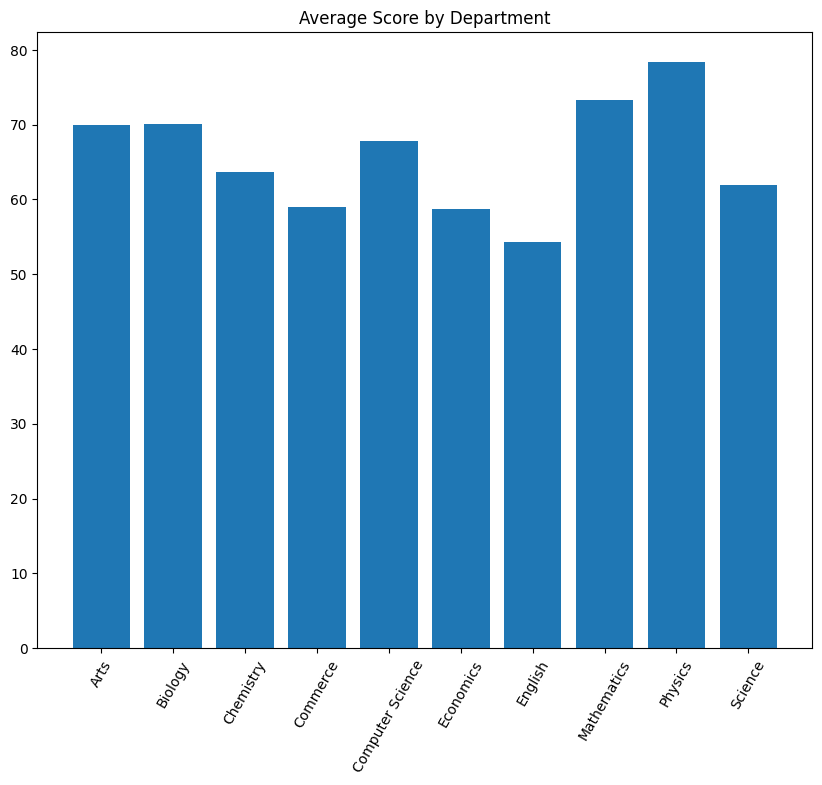

In [ ]:
avg_dept_scr=(df3.groupby('department')['score'].mean())
# print(avg_dept_scr.index)
plt.figure(figsize=(10,8))
plt.bar(avg_dept_scr.index,avg_dept_scr.values)
plt.title("Average Score by Department")
plt.xticks(rotation=60)
plt.show()

# Question 06: [ Marks 10 ]

Using Matplotlib, create a histogram of the score column.

* Use 10 bins
* Add a title: "Distribution of Student Scores"
* Label X-axis as "Score" and Y-axis as "Number of Students"
* Display the chart

## Answer 06:

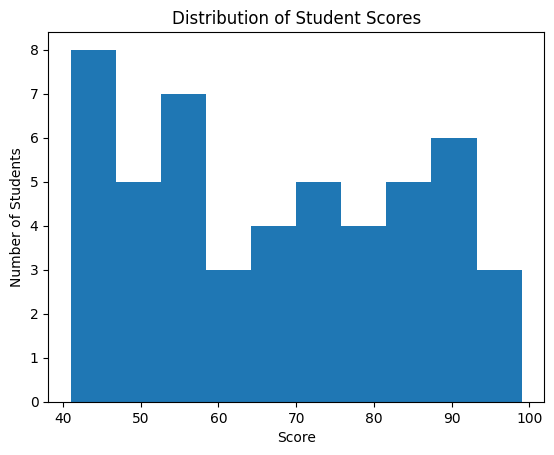

In [ ]:
plt.hist(df3['score'],bins=10)
plt.title("Distribution of Student Scores")
plt.xlabel("Score")
plt.ylabel("Number of Students")
plt.show()

# Question 07: [ Marks 10 ]

Using Matplotlib, create a scatter plot to visualize the relationship between attendance and score.

* X-axis: Attendance (%)
* Y-axis: Score
* Add a title: "Attendance vs Score"
* Label both axes properly
* Display the chart

## Answer 07:


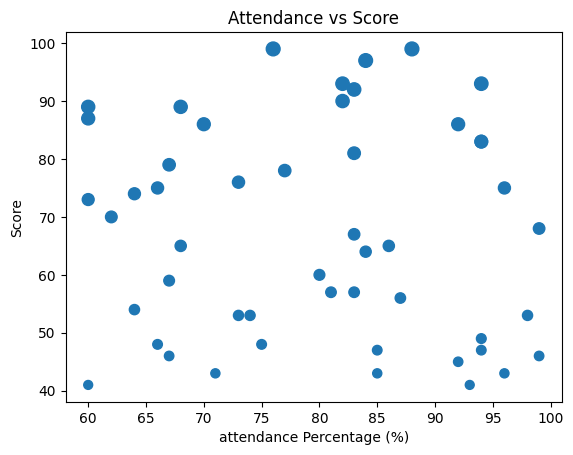

In [ ]:
plt.scatter(df3['attendance'],df3['score'], s=df3['score'])
plt.xlabel("attendance Percentage (%)")
plt.ylabel("Score")
plt.title("Attendance vs Score")
plt.show()

# Question 08: [ Marks 10 ]

Using Seaborn, create a boxplot that shows the distribution of score across different grade categories.

* X-axis: Grade
* Y-axis: Score
* Add a title: "Score Distribution by Grade"
* Display the chart

## Answer 08:

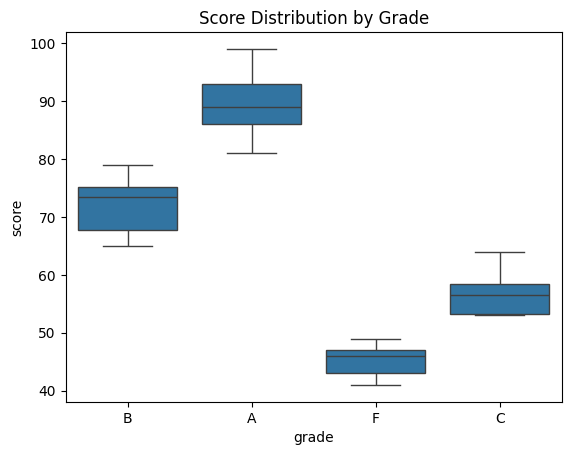

In [ ]:
sns.boxplot(data=df3,x="grade",y="score")
plt.title("Score Distribution by Grade")
plt.show()

# Question 09: [ Marks 10 ]

Using Seaborn, create a countplot showing the number of students in each department.

* Add a title: "Number of Students per Department"
* Display the chart

# Write Answer 09:

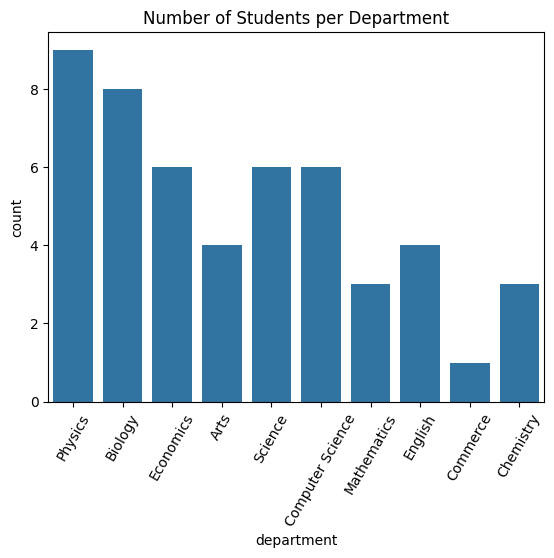

In [ ]:
sns.countplot(data=df3, x="department")
plt.title("Number of Students per Department")
plt.xticks(rotation=60)
plt.show()

# Question 10: [ Marks 10 ]

create a scatter plot showing attendance vs score.

* Color the points by department
* Add a title: "Attendance vs Score by Department"
* Label X-axis as "Attendance (%)" and Y-axis as "Score"
* Display the chart

# Write Answer 10:

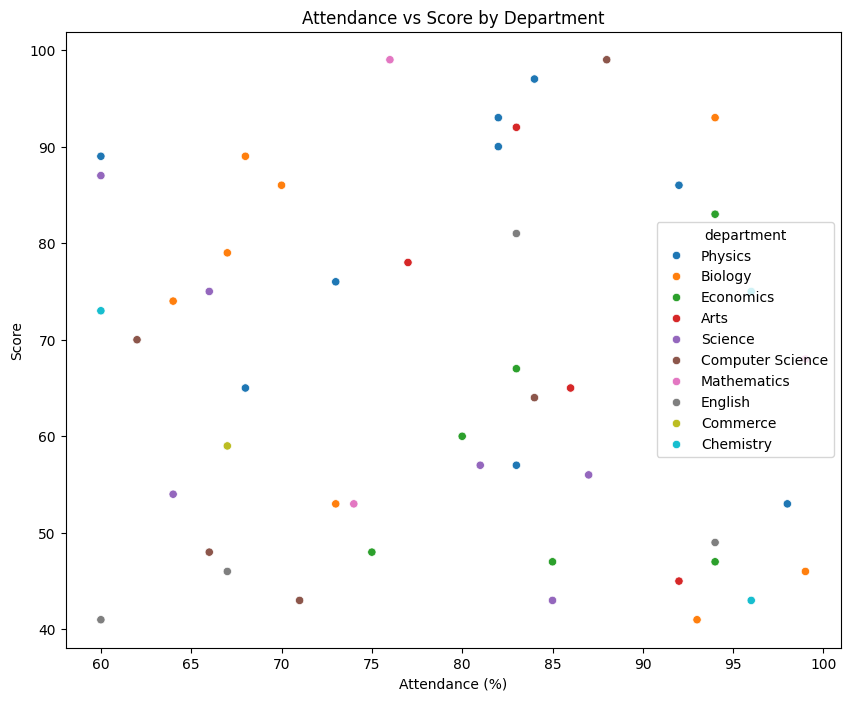

In [ ]:
plt.figure(figsize=(10,8))
sns.scatterplot(data=df3,x="attendance",y="score",hue="department")
plt.title("Attendance vs Score by Department")
plt.xlabel("Attendance (%)")
plt.ylabel("Score")
plt.show()